# 03. Improvements

Every experiment changes one thing against the baseline. Models are chosen by 5-fold stratified CV macro F1 on train; the test set is only reported. All results come from `make train-improved`.

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display

from itg_classification.config import (
    FIGURES_DIR,
    MODELS_DIR,
    RESULTS_DIR,
    TEST_PATH,
    TRAIN_PATH,
)
from itg_classification.features import top_features
from itg_classification.metrics import (
    evaluate,
    load_metrics,
    per_class_table,
)
from itg_classification.preprocess import decode_labels, preprocess_text
from itg_classification.split import load_split
from itg_classification.train_improved import (
    cross_validate,
    experiments_table,
    word_char_logreg,
)

pd.set_option("display.max_colwidth", 120)

## 1. All experiments

In [2]:
saved = load_metrics(RESULTS_DIR / "improved_metrics.json")
table = experiments_table(saved["experiments"], saved["reference"])
table.round(3)

,cv_macro_f1,cv_std,test_macro_f1,test_accuracy,negative_recall,cv_change,test_change
"LinearSVC balanced, words + chars, tuned",0.762,0.025,0.748,0.827,0.522,0.226,0.113
"LogReg balanced, words + chars",0.759,0.019,0.748,0.816,0.638,0.222,0.113
"LogReg balanced, words + chars, tuned",0.759,0.019,0.748,0.816,0.638,0.222,0.113
LinearSVC balanced,0.737,0.018,0.754,0.816,0.551,0.187,0.121
"LogReg balanced, char 2-5 grams",0.734,0.014,0.742,0.806,0.696,0.181,0.105
"LogReg balanced, unigrams",0.723,0.012,0.713,0.780,0.667,0.165,0.061
"LogReg, balanced class weights",0.723,0.017,0.722,0.791,0.638,0.163,0.075
"LogReg balanced, negation tokens",0.722,0.016,0.722,0.792,0.638,0.163,0.075
"LogReg balanced, 1-3 grams",0.721,0.015,0.722,0.791,0.638,0.161,0.075
LinearSVC,0.713,0.009,0.740,0.814,0.464,0.148,0.101


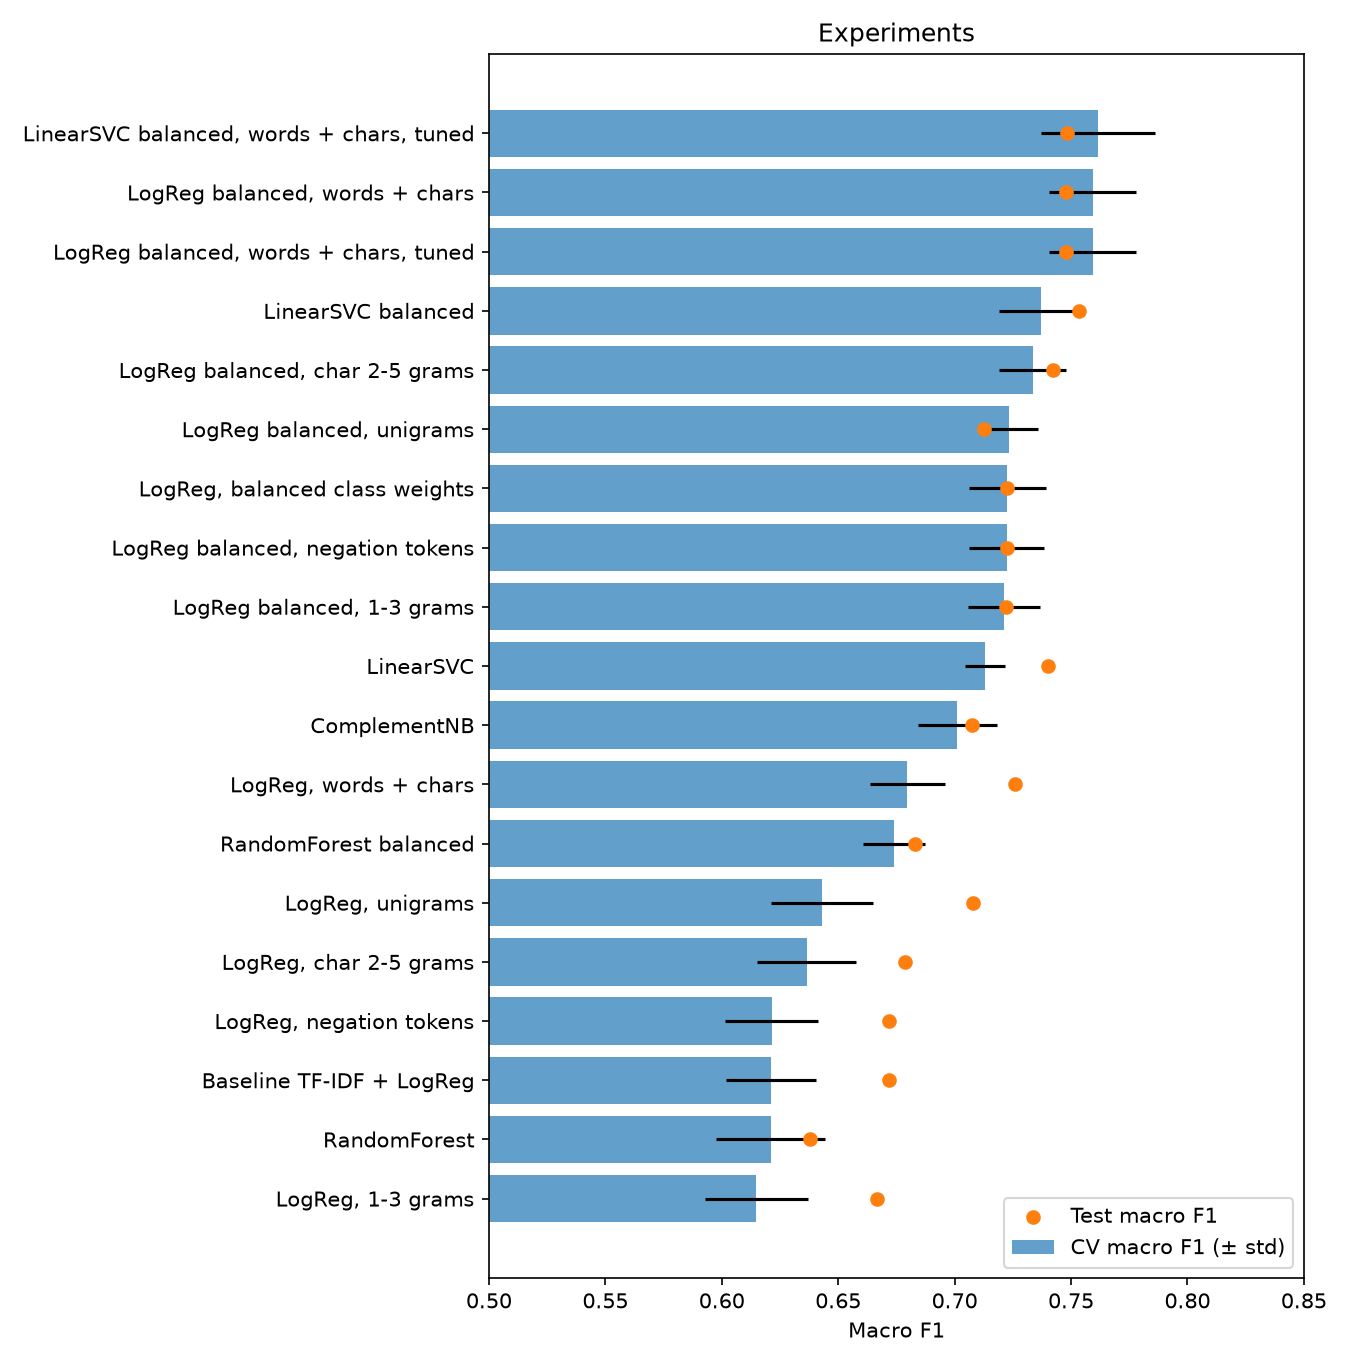

In [3]:
Image(FIGURES_DIR / "experiments_comparison.png")

The fold std is about 0.02, so differences below that are noise. Without class weights the test score is often well above CV: with 69 `negative` test texts a lucky test set inflates the score, which is why we choose by CV.

## 2. What helped and what did not

Each line is one change, compared with the step before it:

| Change | CV macro F1 | Effect |
|---|---|---|
| Baseline TF-IDF + LogReg | 0.621 | |
| + balanced class weights | 0.723 | **+0.102**, the main gain |
| + character 2-5 grams next to words | 0.759 | **+0.036**, about 2 std |
| + tuned `C` and char n-gram range | 0.759 | none: the defaults were best |

Did not help:

- **1-3 grams** and **unigrams only**: no change, trigrams are too rare to carry signal.
- **Negation tokens** (`can't` kept whole): no change, only 21 train texts contain `n't`.
- **ComplementNB** (0.701) and **RandomForest** (0.621-0.674): below the linear models. Trees see only a few of the 11k sparse features of a text.
- **LinearSVC** tuned (0.762) ties with the best LogReg (0.759): the gap is eight times smaller than the std.

## 3. Grid search

In [4]:
for name, rows in saved["grid_search"].items():
    print(name)
    display(pd.DataFrame(rows).round(4))

LogReg balanced, words + chars, tuned


,model__C,tfidf__chars__ngram_range,cv_macro_f1,cv_std
0,1.0,"[2, 5]",0.7593,0.0185
1,10.0,"[2, 5]",0.7572,0.0166
2,3.0,"[2, 5]",0.7569,0.0213
3,10.0,"[3, 5]",0.7562,0.0213
4,3.0,"[3, 5]",0.7541,0.0223
5,30.0,"[3, 5]",0.7530,0.0210
6,1.0,"[3, 5]",0.7529,0.0148
7,30.0,"[2, 5]",0.7512,0.0197
8,0.3,"[2, 5]",0.7353,0.0119
9,0.3,"[3, 5]",0.7341,0.0120


LinearSVC balanced, words + chars, tuned


,model__C,cv_macro_f1,cv_std
0,0.30,0.7615,0.0246
1,0.10,0.7545,0.0159
2,1.00,0.7519,0.0215
3,3.00,0.7487,0.0166
4,0.03,0.7198,0.0151


For LogReg any `C` from 1 to 30 gives the same score, only `C=0.3` regularizes too much. The best point of a grid is slightly optimistic: it is the maximum over several tries on the same folds.

## 4. The best model against the baseline

Chosen: **LogReg balanced, words + chars**, see `BEST_NAME` in `train_improved.py`. It ties with tuned LinearSVC on CV and on test, and wins the tie: more `negative` texts found, a smaller fold std, no tuning needed and probabilities for inference.

In [5]:
best_name = saved["best"]
best_name

'LogReg balanced, words + chars'

In [6]:
baseline = saved["experiments"][saved["reference"]]["test"]
best = saved["experiments"][best_name]["test"]
pd.concat(
    {
        "baseline": per_class_table(baseline)[["precision", "recall", "f1"]],
        "best": per_class_table(best)[["precision", "recall", "f1"]],
    },
    axis=1,
).round(3)

baseline                    best              
         precision recall     f1 precision recall     f1
negative     0.947  0.261  0.409     0.557  0.638  0.595
neutral      0.799  0.908  0.850     0.862  0.887  0.874
positive     0.779  0.735  0.757     0.803  0.749  0.775

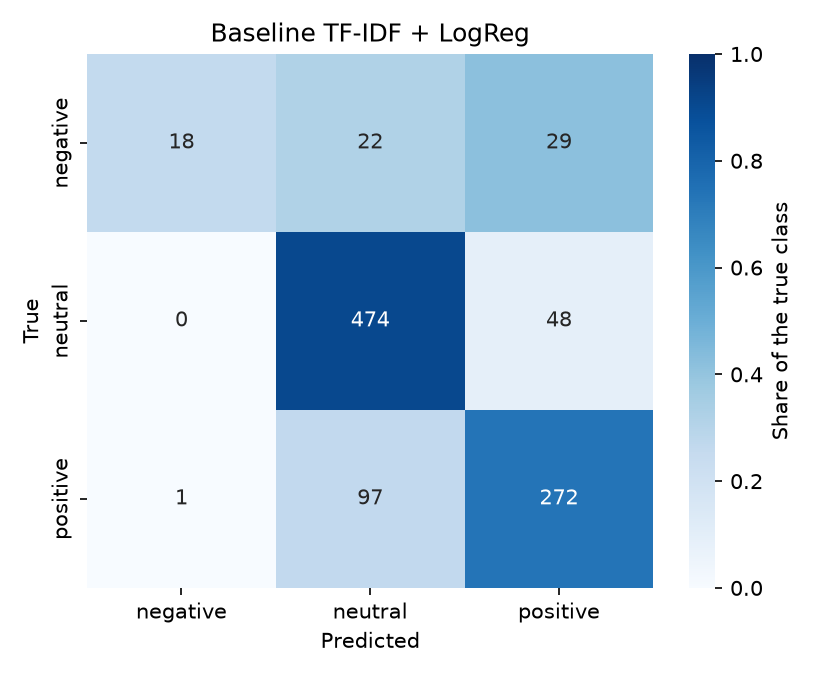

In [7]:
Image(FIGURES_DIR / "confusion_matrix_baseline.png")

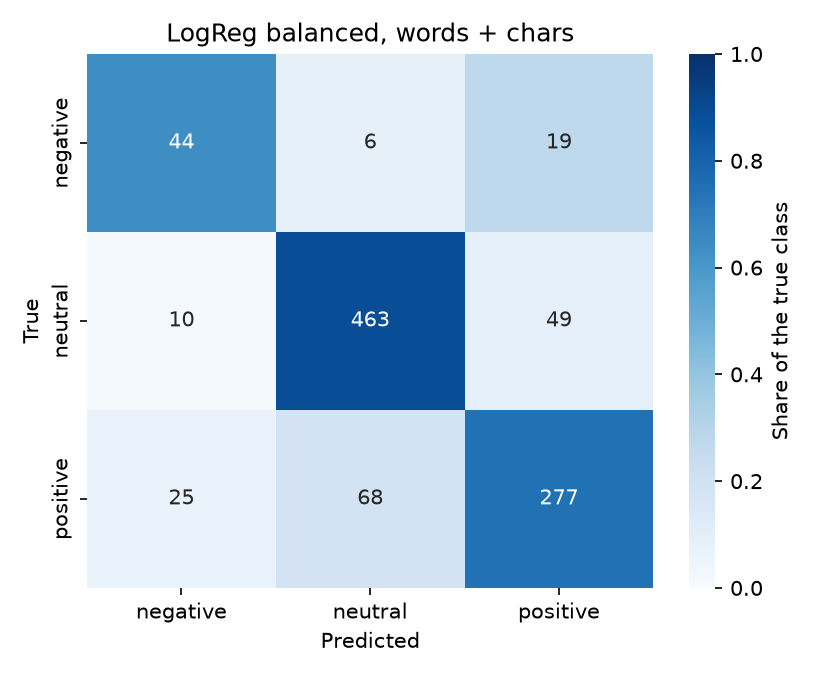

In [8]:
Image(FIGURES_DIR / "confusion_matrix_best.png")

## 5. Why it is better

### Where the gain comes from

In [9]:
test = load_split(TEST_PATH)
tweets = test["raw_text"].str.contains(r"\$[A-Za-z]")
models = {
    "baseline": joblib.load(MODELS_DIR / "baseline.joblib"),
    "best": joblib.load(MODELS_DIR / "best_model.joblib"),
}
pd.DataFrame(
    {
        name: {
            "tweets": np.mean(
                model.predict(test["text"][tweets]) == test["label_id"][tweets]
            ),
            "news": np.mean(
                model.predict(test["text"][~tweets])
                == test["label_id"][~tweets]
            ),
        }
        for name, model in models.items()
    }
).round(3)

,baseline,best
tweets,0.629,0.728
news,0.826,0.832


Accuracy on news sentences is the same, on tweets it rises from 0.63 to 0.73. Most `negative` texts are tweets, so this is where macro F1 grows.

In [10]:
top_features(models["best"], n=15)

,negative,neutral,positive
0,words__down,words__the,words__long
1,chars__ $,words__is,words__up
2,words__short,words__and,words__buy
3,words__lower,words__of,words__higher
4,words__spy,chars__.,words__rise
5,words__price,words__be,words__positive
6,words__fall,words__of the,words__year
7,words__shell,chars__ the,chars__ $
8,words__share price,chars__the,words__in the
9,words__drop,chars__ is,words__with


Character n-grams add word parts like `down`, `dow`, `..` and the cashtag start ` $`. Do they work only through the `$` sign? Removing it from every text and training again:

In [11]:
train = load_split(TRAIN_PATH)
no_dollar = {
    name: part.assign(text=part["text"].str.replace("$", "", regex=False))
    for name, part in [("train", train), ("test", test)]
}
model = word_char_logreg().fit(
    no_dollar["train"]["text"], no_dollar["train"]["label_id"]
)
{
    "cv_macro_f1": cross_validate(word_char_logreg(), no_dollar["train"])
    .mean()
    .round(3),
    "test_macro_f1": round(
        evaluate(
            no_dollar["test"]["label_id"],
            model.predict(no_dollar["test"]["text"]),
        )["macro_f1"],
        3,
    ),
}

{'cv_macro_f1': np.float64(0.758), 'test_macro_f1': 0.743}

The scores barely change: CV 0.759 → 0.758, test 0.748 → 0.743, far below the fold std. So the gain is not the `$` sign. Character n-grams help on tweets because tweets are short, informal and full of word forms, tickers and typos (`dow`, `falling`, `b4`): word parts match them where whole words do not.

### What did not change

In [12]:
new_texts = [
    "Profit fell sharply in the third quarter",
    "The company reported a net loss of EUR 5 million",
    "Sales rose 20% year-on-year",
    "The annual general meeting will be held in Helsinki",
]
processed = [preprocess_text(text) for text in new_texts]
pd.DataFrame(
    {
        name: decode_labels(model.predict(processed))
        for name, model in models.items()
    },
    index=new_texts,
)

,baseline,best
Profit fell sharply in the third quarter,positive,positive
The company reported a net loss of EUR 5 million,neutral,neutral
Sales rose 20% year-on-year,positive,positive
The annual general meeting will be held in Helsinki,neutral,neutral


Clear negative news sentences are still wrong: *profit fell* is `positive`, *net loss* is `neutral`. Only 19 of the 69 `negative` test texts are news, so the model has few examples of negative news to learn from. That is the main question for the error analysis.

## 6. Summary

| Method | CV macro F1 | Test macro F1 | Test change |
|---|---|---|---|
| Baseline TF-IDF + LogReg | 0.621 | 0.672 | |
| LogReg, balanced class weights | 0.723 | 0.722 | +7.5% |
| **LogReg balanced, words + chars** | **0.759** | **0.748** | **+11.3%** |
| LinearSVC balanced, words + chars, tuned | 0.762 | 0.748 | +11.3% |

- The goal of +5% (macro F1 0.706) is reached: **0.748, +11.3%**.
- Two changes did the work: class weights (`negative` recall 0.26 → 0.64) and character n-grams (tweets 0.63 → 0.73 accuracy).
- Tuning, other n-grams, negation tokens and other models did not beat it.
- The best model is saved to `models/best_model.joblib`.